# Task-1: Setup
Importing modules and Files

In [11]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb

In [12]:
train = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
submission = pd.read_csv('../data/raw/sample_submission.csv')

# Task-2 :First Look

In [13]:
train.head() ; test.head()
train.info() ; test.info()
train.describe() ;test.describe()
train.shape ; test.shape
train.columns.difference(test.columns) # to check if there are any columns in train that are not in test

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  object 
 9   City_Type                    668665 non-null  object 
 10  Current_Car_Type             668665 non-null  object 
 11  Home_Charging_Possible       668665 non-null  object 
 12  Subsidy_Available            668665 non-null  object 
 13 

Index(['Will_Buy_EV'], dtype='object')

# Task-3 :Target check

In [14]:
train['Will_Buy_EV'].value_counts(normalize=True) # to check the distribution of the target variable


Will_Buy_EV
No     0.825355
Yes    0.174645
Name: proportion, dtype: float64

# Task-4 :Data quality

In [15]:
train.isna().sum()
test.isna().sum() 
train.duplicated().sum()
train.columns.dtype 
test.columns.dtype

dtype('O')

In [16]:
features = train.drop(columns = ['id','Will_Buy_EV'])
num_cols_train = features.select_dtypes(include=np.number).columns.tolist()
cat_cols_train = features.select_dtypes(exclude=np.number).columns.tolist()
print(len(num_cols_train), len(cat_cols_train), features.shape[1])
print(set(num_cols_train + cat_cols_train) == set(test.columns))

7 6 13
False


# Task-5 : Quick EDA

In [17]:
import matplotlib.pyplot as plt

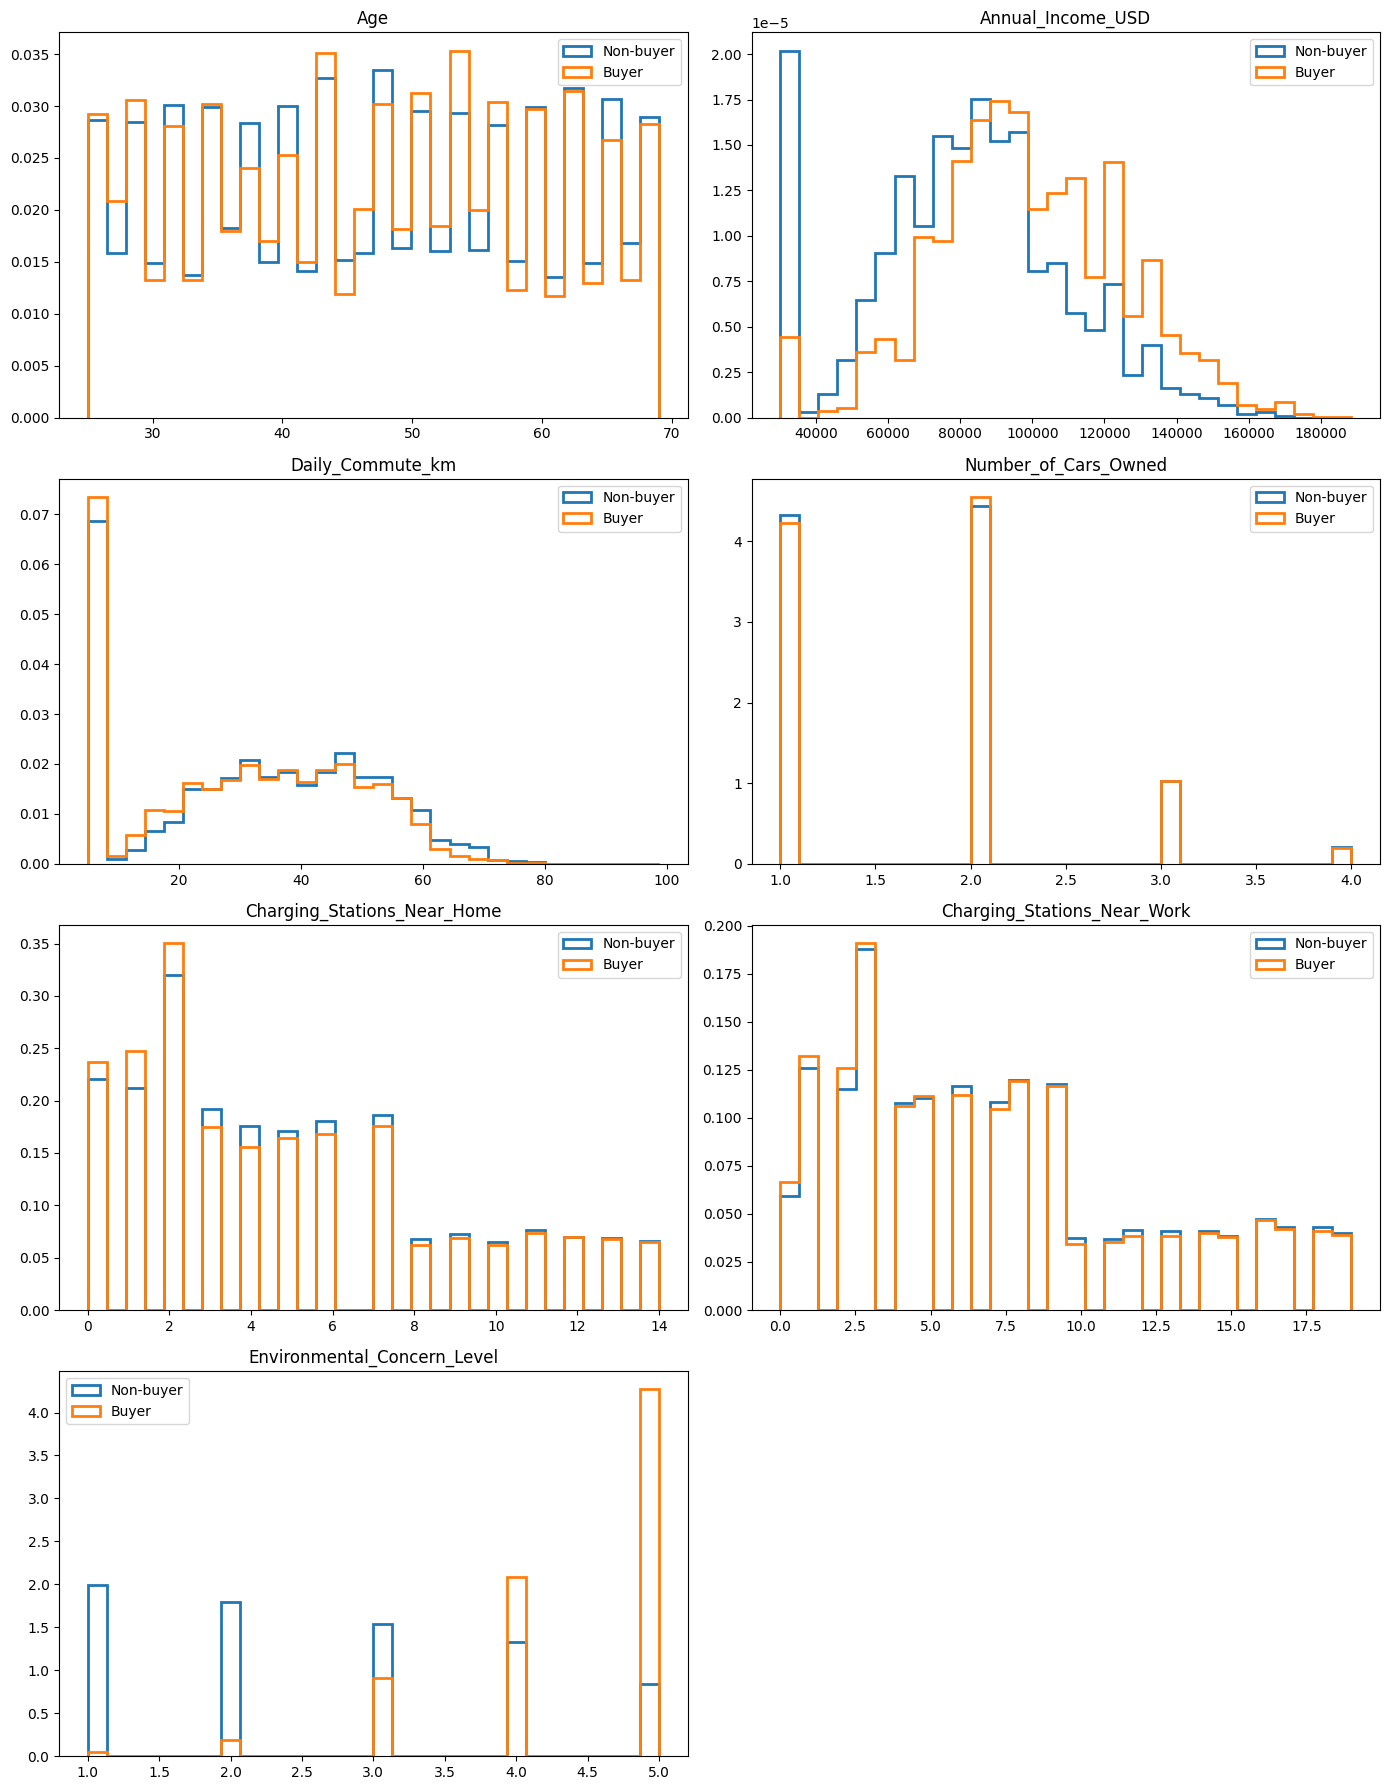

In [18]:
y = (train['Will_Buy_EV'] == 'Yes').astype(int)

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.ravel()

for ax, col in zip(axes, num_cols_train):
    bins = np.linspace(train[col].min(), train[col].max(), 31)
    ax.hist(train.loc[y == 0, col], bins=bins, density=True,
            histtype='step', linewidth=2, label='Non-buyer')
    ax.hist(train.loc[y == 1, col], bins=bins, density=True,
            histtype='step', linewidth=2, label='Buyer')
    ax.set_title(col)
    ax.legend()

axes[-1].set_visible(False)   # 7 columns, 8 slots, so hide the empty one
plt.tight_layout()
plt.show()

['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']


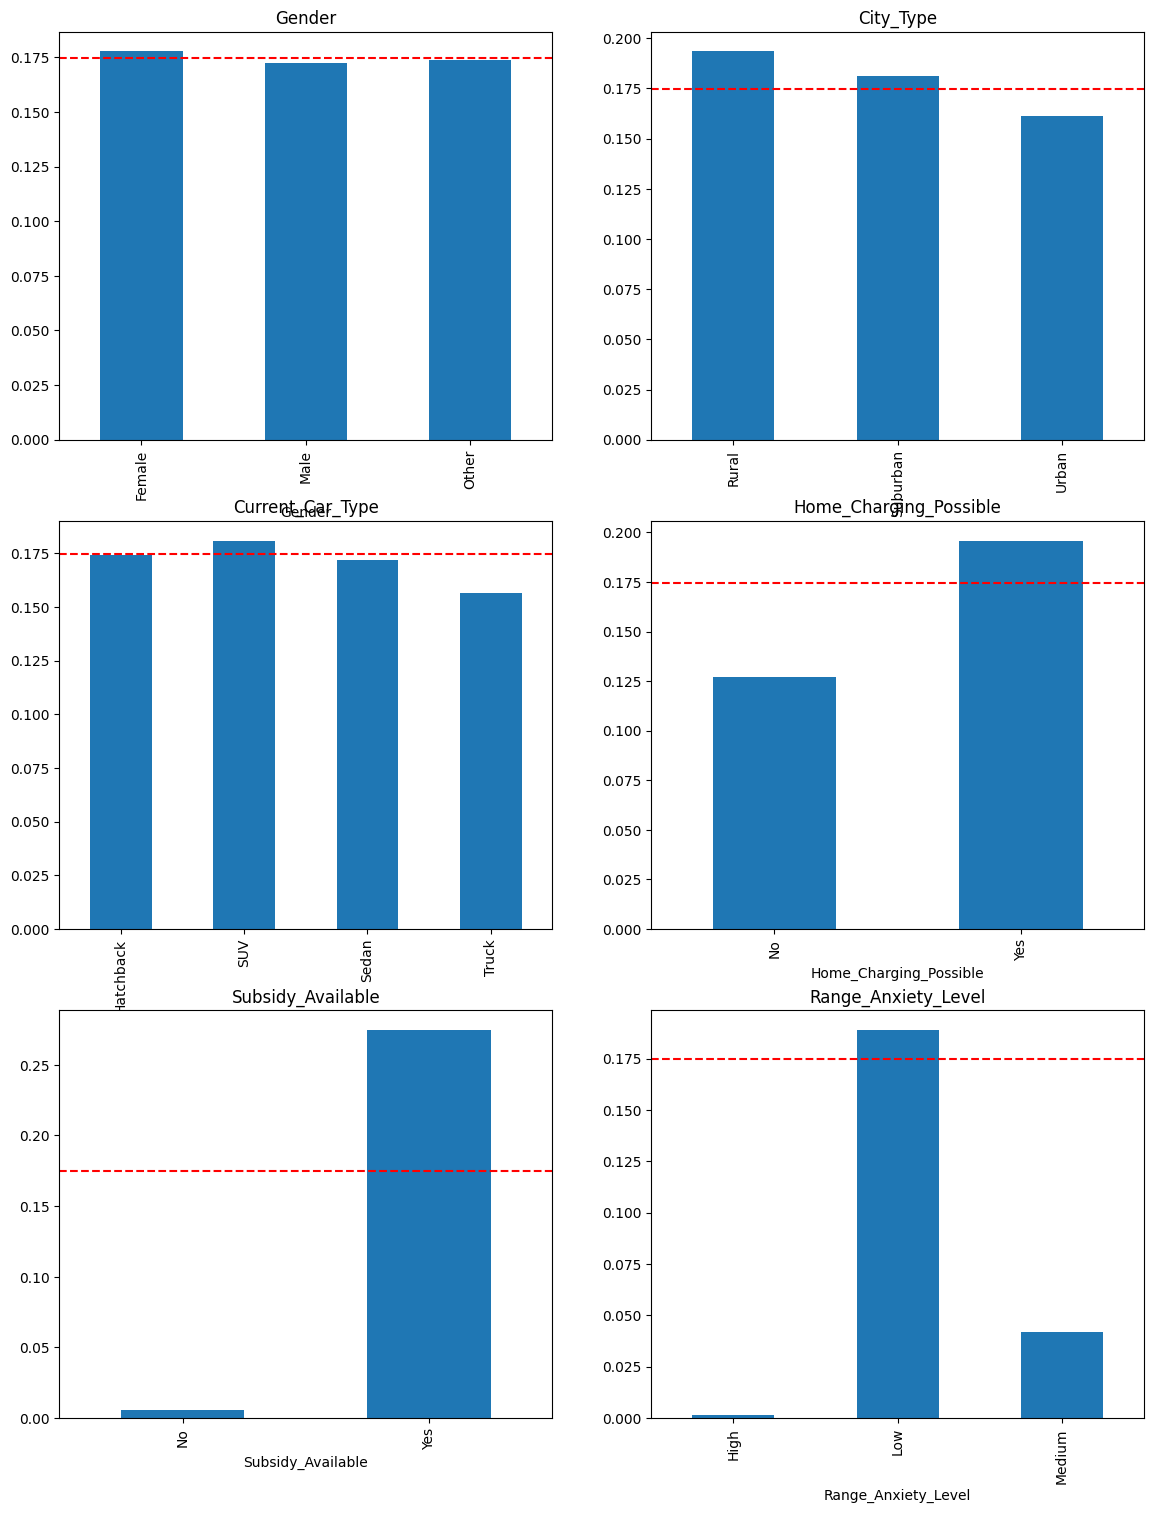

In [19]:
print(cat_cols_train) # quick check of the categorical columns
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.ravel()

for ax, col in zip(axes, cat_cols_train):
    y.groupby(train[col]).mean().plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.axhline(y.mean(), color='red', linestyle='--')

# Most related buying features are:
1.Subsidy_Available

2.Range_Anxiety_Level

3.Current_Car_Type

4.Home_Charging_Possible

# Task-6 : Preprocessing

--Encoded Categorical Columns

--And applying transform on train and test data

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cat_cols_train_enc = pd.DataFrame()
cat_cols_test_enc = pd.DataFrame()
for c in cat_cols_train:
    cat_cols_train_enc[c] = le.fit_transform(train[c])
    cat_cols_test_enc[c] = le.transform(test[c])
x = pd.DataFrame(cat_cols_train_enc, columns=cat_cols_train)
y = y.copy()
print(x.shape,'\n', x.head(5))

(668665, 6) 
    Gender  City_Type  Current_Car_Type  Home_Charging_Possible  \
0       1          1                 2                       1   
1       1          0                 1                       1   
2       0          2                 2                       0   
3       1          1                 0                       1   
4       1          1                 0                       1   

   Subsidy_Available  Range_Anxiety_Level  
0                  0                    1  
1                  0                    1  
2                  1                    1  
3                  0                    1  
4                  0                    1  
